# 07 · Compare depth, RAFT, GMA, and AnimeInbet

Use fixed validation pairs to test depth-weighted motion, compare RAFT-small with AnimeRun-trained RAFT and GMA, and compare their U-Net predictions with AnimeInbet. The unmasked epoch-13 U-Net stays fixed.

**Setup:** Kaggle with Stage 1 data, the unmasked epoch-13 checkpoint, and Internet for model downloads. The AnimeInbet comparison also uses original ML240 endpoint drawings and line graphs.

**Saves:** Validation scores, depth and motion comparisons, matched prediction panels, and an ink-cutoff comparison.

In [ ]:
from pathlib import Path

datasets = Path("/kaggle/input/datasets/epicfaez")
DATA = datasets / "interframes-stage1-output/interframes_tf_stage1"
MODEL = datasets / "interframes-stage2-ink15/interframes_tf_stage2_ink15"
DEPTH_MODEL = "depth-anything/Depth-Anything-V2-Small-hf"
OUT = Path("/kaggle/working/interframes_depth07")

N_CASES, SEED = 20, 42
GAP = None  # Set to 4 for larger gaps.
CASE_IDS = []  # Optional validation IDs to inspect instead of sampling.
STRENGTH = 3.0  # Zero reproduces the ordinary warps.
SHOW = 4  # All panels are saved; this many are displayed.

## Load epoch 13 and choose validation pairs

Load the saved U-Net and Stage 1 motion. By default, choose each pair from a different sequence.

In [ ]:
import hashlib, json, random, sys
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
sys.path.insert(0, str(DATA / "modules"))
import data as raster
import learning


def read_json(path):
    return json.loads(path.read_text())


state = read_json(MODEL / "training_state.json")
cfg = state["run_config"]
fingerprint = read_json(DATA / "stage1_complete.json")["fingerprint"]
assert (
    state.get("experiment") == "epoch10_ink30_to_ink15"
    and cfg["positive_weight"] == 15
    and cfg["data_fingerprint"] == fingerprint
    and cfg["feature_version"] == learning.FEATURE_VERSION
), "Check both dataset paths."
if state["completed_epochs"] == 13 and not state.get("partial"):
    checkpoint = MODEL / "last.keras"
elif state.get("best_epoch") == 13:
    checkpoint = MODEL / "best.keras"
else:
    raise ValueError("Attach the unmasked ink-15 output containing epoch 13.")
net = tf.keras.models.load_model(checkpoint, compile=False)
entry = next(h for h in state["history"] if h["epoch"] == 13)
digest = hashlib.sha256()
for v in net.weights:
    a = v.numpy()
    for part in (str(a.shape).encode(), str(a.dtype).encode(), a.tobytes()):
        digest.update(part)
assert (
    net.name == "interframes_unet" and digest.hexdigest() == entry["weights_digest"]
), "Epoch 13 weights mismatch."

rows = [r for r in raster.read_records(DATA) if r["split"] == "val"]
if CASE_IDS:
    by_id = {r["id"]: r for r in rows}
    cases = [by_id[k] for k in dict.fromkeys(CASE_IDS)]
else:
    groups = defaultdict(list)
    for r in rows:
        if GAP is None or r["gap"] == GAP:
            groups[r["sequence"]].append(r)
    rng = random.Random(SEED)
    cases = [
        rng.choice(groups[s])
        for s in rng.sample(sorted(groups), min(N_CASES, len(groups)))
    ]
assert cases and 0 <= STRENGTH <= 12, (
    "Select validation cases and a strength in [0, 12]."
)
flows = raster.open_flows(DATA, "val")
done = np.load(DATA / "flows/val_done.npy", mmap_mode="r")
assert all(done[r["cache_index"]] for r in cases), "Selected flows are incomplete."
settings = dict(
    ids=[r["id"] for r in cases],
    strength=STRENGTH,
    depth_model=str(DEPTH_MODEL),
    weights_sha256=digest.hexdigest(),
    fingerprint=fingerprint,
    cutoff=0.5,
    tolerance_px=2,
)
tag = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:10]
folder = OUT / tag
folder.mkdir(parents=True, exist_ok=True)
(folder / "settings.json").write_text(json.dumps(settings, indent=2))
print(checkpoint, "| epoch 13 |", len(cases), "validation pairs |", folder)

/kaggle/input/datasets/epicfaez/interframes-stage2-ink15/interframes_tf_stage2_ink15/last.keras | epoch 13 | 20 validation pairs | /kaggle/working/interframes_depth07/65c608884d


## Estimate depth in each endpoint

Use [Depth Anything V2 Small](https://huggingface.co/depth-anything/Depth-Anything-V2-Small-hf) to estimate which parts appear nearer. Yellow marks nearer regions within each drawing. Inspect whether crossing body parts receive different depths.

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Endpoint depth:   0%|          | 0/20 [00:00<?, ?it/s]

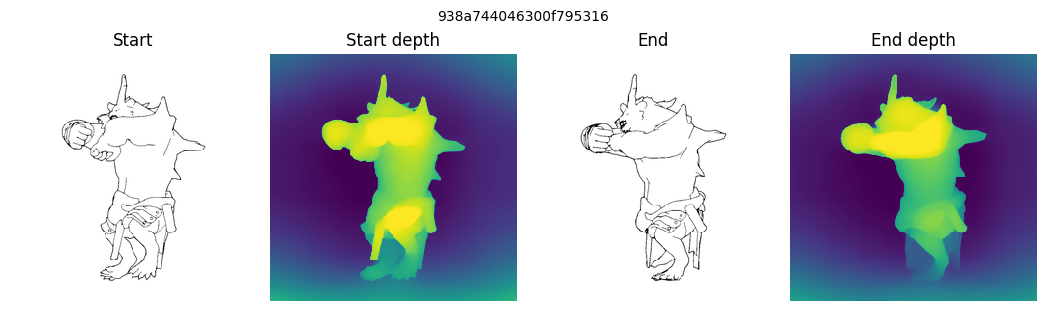

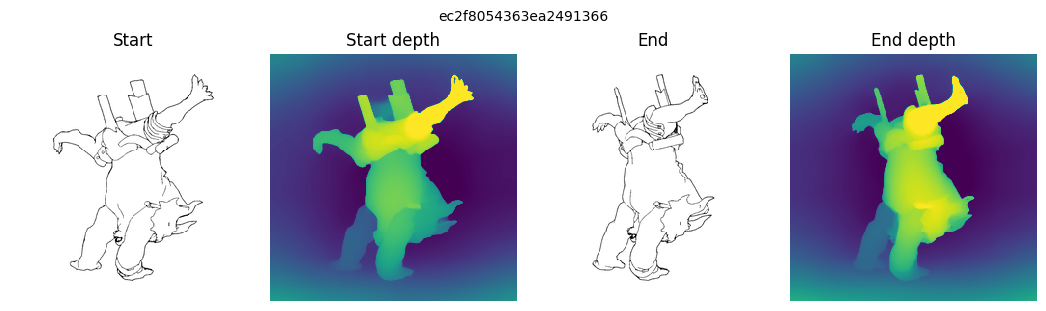

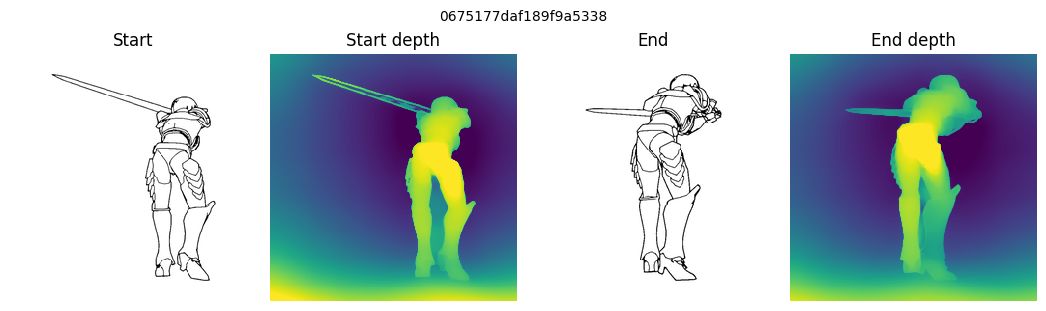

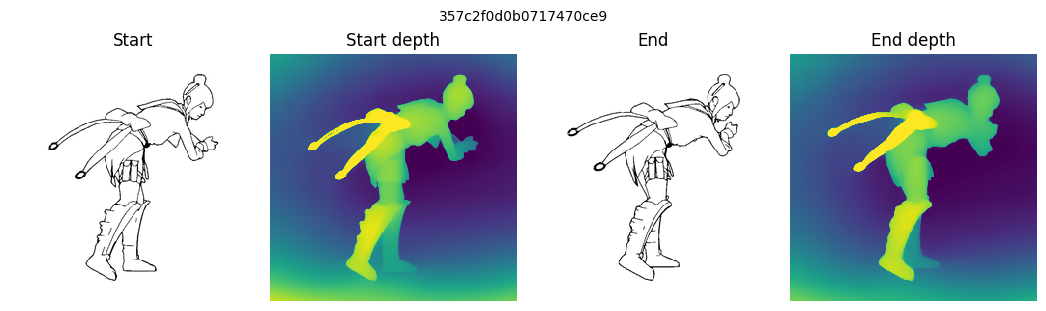

In [ ]:
import torch
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

device = "cuda" if torch.cuda.is_available() else "cpu"
processor = AutoImageProcessor.from_pretrained(DEPTH_MODEL)
depth_net = AutoModelForDepthEstimation.from_pretrained(DEPTH_MODEL).to(device).eval()
depths = {}


@torch.inference_mode()
def endpoint_depth(rel):
    if rel not in depths:
        with Image.open(DATA / rel) as im:
            image = im.convert("RGB")
        inputs = processor(images=image, return_tensors="pt").to(device)
        d = depth_net(**inputs).predicted_depth[:, None]
        resized = torch.nn.functional.interpolate(
            d.float(),
            size=(image.height, image.width),
            mode="bilinear",
            align_corners=False,
        )
        raw = resized[0, 0].cpu().numpy()
        if not np.isfinite(raw).all():
            raise ValueError(f"Invalid depth for {rel}")
        lo, hi = np.percentile(raw, [2, 98])
        depths[rel] = np.clip((raw - lo) / max(float(hi - lo), 1e-6), 0, 1).astype(
            "float32"
        )
    return depths[rel]


def panel(views, title, path, show):
    fig, axes = plt.subplots(
        1, len(views), figsize=(2.6 * len(views), 3), constrained_layout=True
    )
    for ax, (label, image, cmap) in zip(axes, views):
        ax.imshow(image, cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(label)
        ax.axis("off")
    fig.suptitle(title, fontsize=10)
    fig.savefig(path, dpi=130)
    if show:
        plt.show()
    plt.close(fig)


for i, r in enumerate(tqdm(cases, desc="Endpoint depth")):
    views = []
    for label, key in (("Start", "a"), ("End", "b")):
        views += [
            (label, raster.read_ink(DATA / r[key]), "gray_r"),
            (label + " depth", endpoint_depth(r[key]), "viridis"),
        ]
    panel(views, str(r["id"]), folder / f"{i + 1:02d}_depth.png", i < SHOW)

## Test depth-weighted rough drawings

When several pixels land in the same place, give nearer pixels more weight. Replace only the two rough middle-drawing inputs; use the same U-Net and ink cutoff for both predictions.

Paired predictions:   0%|          | 0/20 [00:00<?, ?it/s]

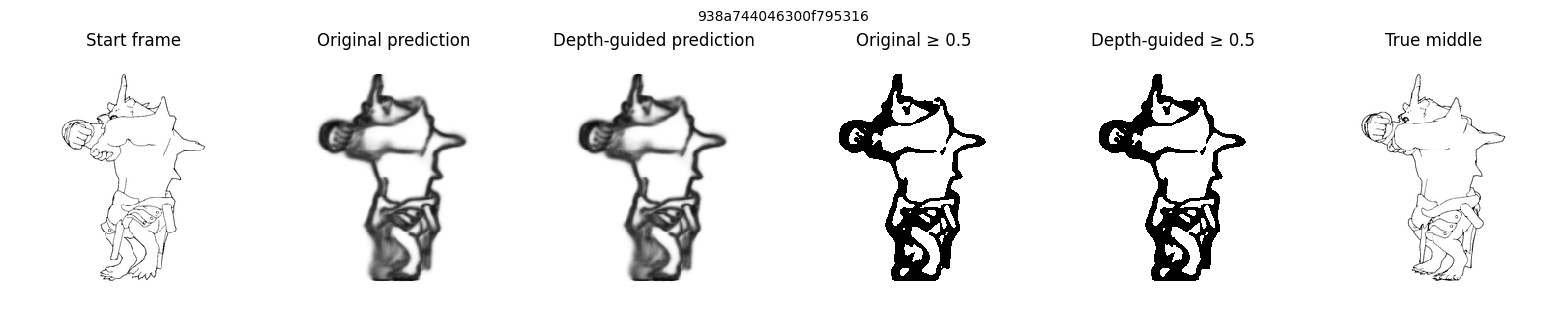

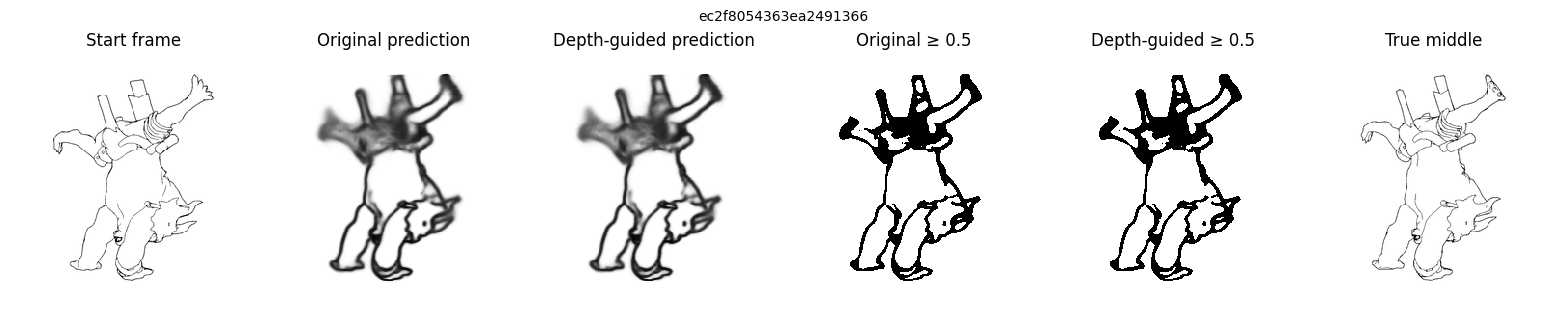

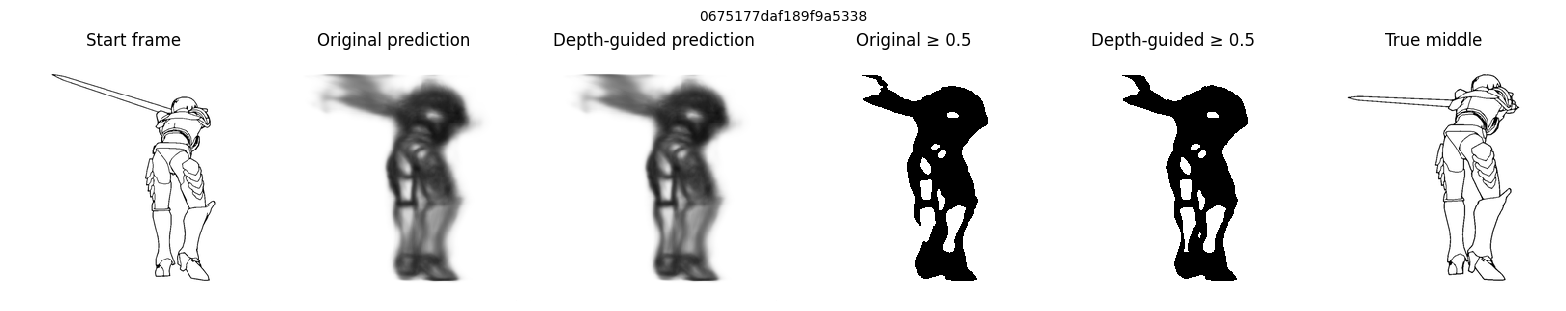

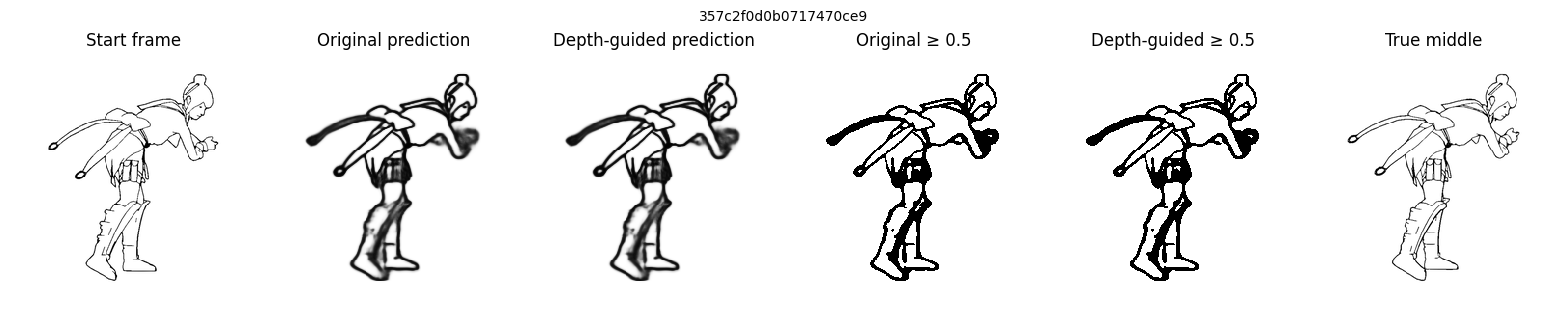

In [ ]:
def depth_warp(ink, flow, depth, coverage):
    # Geometric normalization is identical in both splats and cancels in their ratio.
    priority = np.exp(STRENGTH * depth)
    numerator, _ = raster.forward_splat(ink * priority, flow)
    denominator, _ = raster.forward_splat(priority, flow)
    return np.divide(numerator, denominator, out=np.zeros_like(ink), where=coverage > 0)


records = []
for i, r in enumerate(tqdm(cases, desc="Paired predictions")):
    low = flows[r["cache_index"]]
    original = raster.row_features(DATA, r, flows)
    guided = original.copy()
    for j, key in enumerate(("a", "b")):
        flow = raster.upsample_low(low[j], original.shape[0]).transpose(2, 0, 1)
        ink, coverage = original[..., j], original[..., 6 + j]
        if i == 0:
            neutral = depth_warp(ink, flow, np.zeros_like(ink), coverage)
            np.testing.assert_allclose(neutral, original[..., 2 + j], atol=2e-6)
        guided[..., 2 + j] = depth_warp(ink, flow, depths[r[key]], coverage)

    batch = np.stack([original, guided])
    pred = tf.sigmoid(tf.cast(net(batch, training=False), tf.float32)).numpy()[..., 0]
    if not np.isfinite(pred).all():
        raise ValueError(f"Invalid prediction for {r['id']}")
    target = raster.read_ink(DATA / r["target"])
    views = [
        ("Start frame", original[..., 0], "gray_r"),
        ("Original prediction", pred[0], "gray_r"),
        ("Depth-guided prediction", pred[1], "gray_r"),
        ("Original ≥ 0.5", pred[0] >= 0.5, "gray_r"),
        ("Depth-guided ≥ 0.5", pred[1] >= 0.5, "gray_r"),
        ("True middle", target, "gray_r"),
    ]
    panel(views, str(r["id"]), folder / f"{i + 1:02d}_prediction.png", i < SHOW)
    for method, drawing in zip(("original", "depth"), pred):
        score = raster.line_scores(drawing, target, threshold=0.5, tolerance=2)
        records.append(
            dict(
                id=r["id"],
                sequence=r["sequence"],
                gap=r["gap"],
                method=method,
                target_ink_fraction=float((target >= 0.5).mean()),
                **score,
            )
        )
scores = pd.DataFrame(records)
scores.to_csv(folder / "per_pair.csv", index=False)

## Compare the depth results

Compare line F1, average line distance (Chamfer), average pixel error (MAE), and predicted-to-reference ink ratio. Higher F1, lower distance/error, and an ink ratio near 1 are preferred. Inspect the panels for missing or doubled lines.

In [ ]:
means = scores.groupby("method").mean(numeric_only=True)
means["ink_ratio"] = means.ink_fraction / means.target_ink_fraction
summary = means[["line_f1", "chamfer_px", "mae", "ink_ratio"]].copy()
summary.loc["depth minus original"] = summary.loc["depth"] - summary.loc["original"]
display(summary.round(5))
summary.to_csv(folder / "summary.csv")
paired = scores.pivot(index="id", columns="method", values="line_f1")
delta = paired.depth - paired.original
print(
    f"Line F1: {(delta > 1e-6).sum()} improved, {(delta < -1e-6).sum()} declined, "
    f"{(delta.abs() <= 1e-6).sum()} tied. Panels and CSVs: {folder}"
)

,line_f1,chamfer_px,mae,ink_ratio
method,,,,
depth,0.78416,1.32059,0.09426,4.88746
original,0.78460,1.31620,0.09346,4.84353
depth minus original,-0.00044,0.00439,0.00080,0.04393


Line F1: 7 improved, 12 declined, 1 tied. Panels and CSVs: /kaggle/working/interframes_depth07/65c608884d


## Prepare RAFT and GMA

Download the two motion-model implementations and their AnimeRun checkpoints. Run them in separate processes to keep their imports independent.

In [ ]:
import subprocess
import sys
from huggingface_hub import hf_hub_download

flow_dir = folder / "flow_comparison"
flow_dir.mkdir(exist_ok=True)
repos = Path("/kaggle/temp/animerun_models")
repos.mkdir(parents=True, exist_ok=True)

specs = {
    "RAFT": ("princeton-vl/RAFT", "20000_raft-animerun-v2-ft_again.pth"),
    "GMA": ("zacjiang/GMA", "20000_gma-animerun-v2-ft.pth"),
}
checkpoints = {}
for name, (repo, filename) in specs.items():
    if not (repos / name / "core").is_dir():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                f"https://github.com/{repo}.git",
                str(repos / name),
            ],
            check=True,
        )
    checkpoints[name] = hf_hub_download("dreMaz/AnimeRun_ckpt", filename)

(flow_dir / "cases.json").write_text(json.dumps(cases))
print(f"Ready: {len(cases)} validation pairs.")

Cloning into '/kaggle/temp/animerun_models/RAFT'...


20000_raft-animerun-v2-ft_again.pth: reconstructing file:   0%|          |  0.00B / 21.1MB            

20000_raft-animerun-v2-ft_again.pth: downloading bytes:           |  0.00B            

Cloning into '/kaggle/temp/animerun_models/GMA'...


20000_gma-animerun-v2-ft.pth: reconstructing file:   0%|          |  0.00B / 23.8MB            

20000_gma-animerun-v2-ft.pth: downloading bytes:           |  0.00B            

Ready: 20 validation pairs.


## Write the motion worker

Save a worker that estimates motion in both directions and writes compact grids compatible with Stage 1. Keep `%%writefile` as the first line of its code cell.

In [ ]:
%%writefile /kaggle/working/animerun_flow07.py
import argparse, json, sys
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from tqdm import tqdm

name, repo, checkpoint, data, out, steps = sys.argv[1:]
root, out = Path(data), Path(out)
sys.path.insert(0, str(Path(repo) / "core"))
if name == "RAFT":
    from raft import RAFT as FlowModel
else:
    from network import RAFTGMA as FlowModel

args = argparse.Namespace(
    small=False,
    mixed_precision=False,
    alternate_corr=False,
    dropout=0.0,
    num_heads=1,
    position_only=False,
    position_and_content=False,
)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = FlowModel(args)
weights = torch.load(checkpoint, map_location="cpu", weights_only=True)
model.load_state_dict(
    {k.removeprefix("module."): v for k, v in weights.items()}, strict=True
)
model.to(device).eval()


def frame(path):
    with Image.open(root / path) as im:
        rgb = np.array(im.convert("RGB"))
    return torch.from_numpy(rgb).permute(2, 0, 1).float()


cases = json.loads((out / "cases.json").read_text())
with torch.inference_mode():
    for i, row in enumerate(tqdm(cases, desc=f"AnimeRun {name}")):
        dest = out / f"{name}_{i:03d}.npy"
        if dest.exists():
            continue
        pair = torch.stack([frame(row["a"]), frame(row["b"])]).to(device)
        # Batch item 0 is start→end; item 1 is end→start.
        low, _ = model(pair, pair.flip(0), iters=int(steps), test_mode=True)
        h, w = pair.shape[-2:]
        assert low.shape == (2, 2, h // 8, w // 8) and torch.isfinite(low).all()
        tmp = dest.with_suffix(".part.npy")
        np.save(tmp, low.permute(0, 2, 3, 1).cpu().numpy().astype(np.float16))
        tmp.replace(dest)

Writing /kaggle/working/animerun_flow07.py


## Compare three motion sources, then add depth

Compare cached RAFT-small, RAFT, and GMA with depth weighting off. The following cell repeats the comparison with depth weighting. Panels show endpoints, rough middle drawings, predictions, and the true middle.

AnimeRun GMA: 100%|██████████| 20/20 [00:00<00:00, 37052.16it/s]


Compare U-Net outputs:   0%|          | 0/20 [00:00<?, ?it/s]

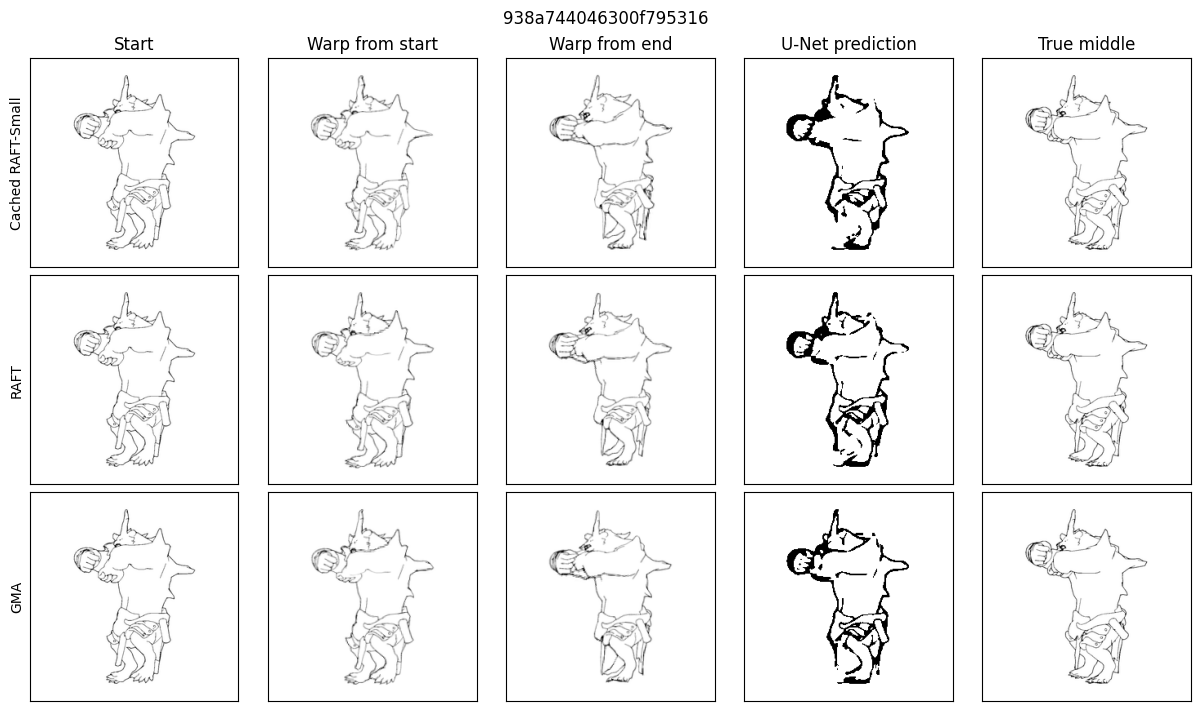

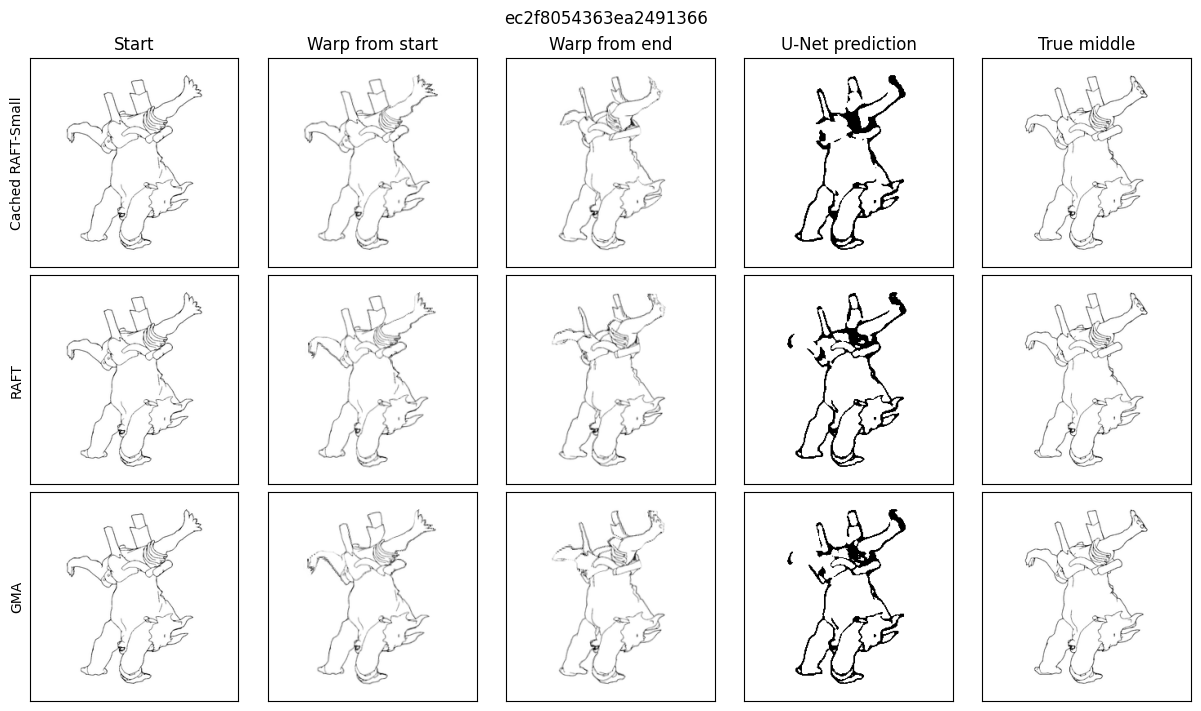

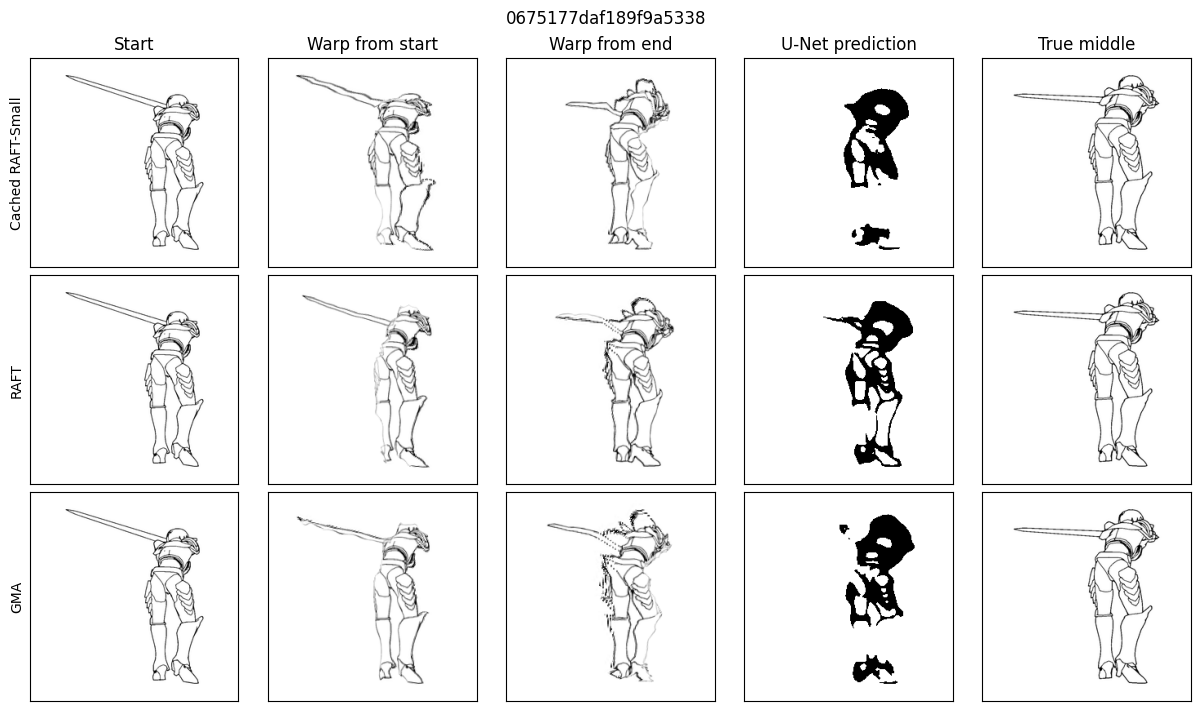

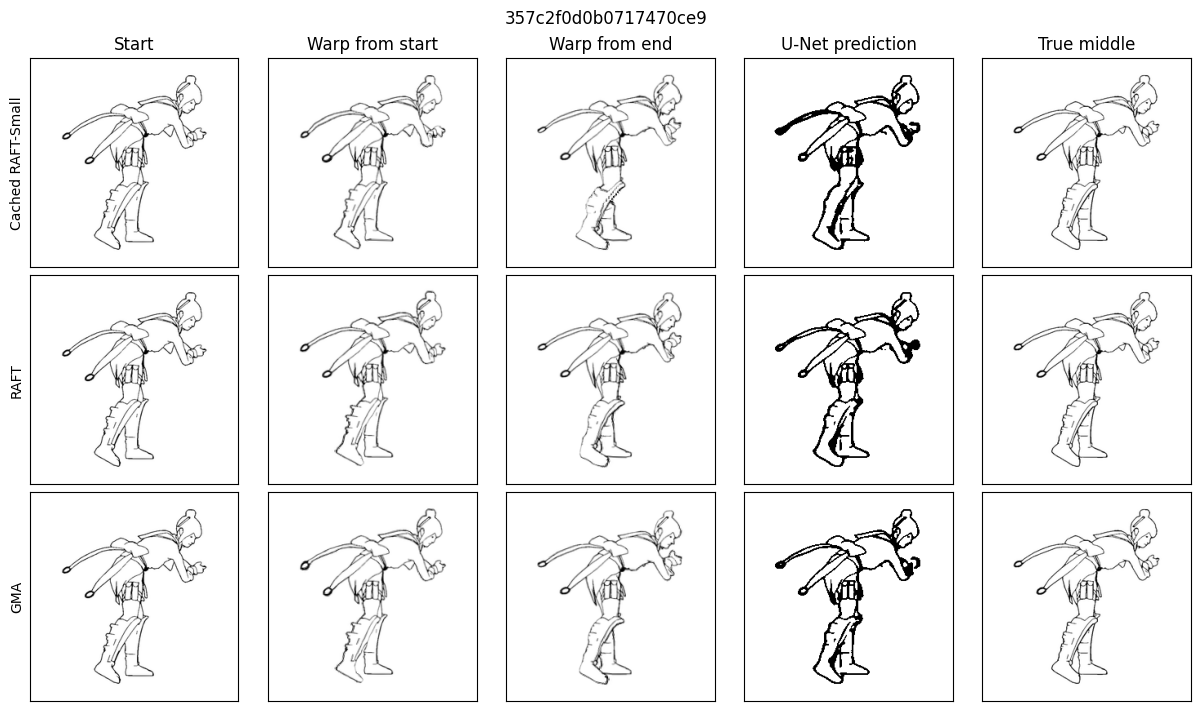

,line_f1,chamfer_px,mae,ink_ratio
method,,,,
Cached RAFT-Small,0.78459,1.31630,0.09346,4.84353
RAFT,0.79911,1.31033,0.08468,4.31532
GMA,0.80095,1.28008,0.08509,4.39971


Saved: /kaggle/working/interframes_depth07/65c608884d/flow_comparison


In [ ]:
steps = str(read_json(DATA / "config.json").get("raft_iterations", 12))
for name in specs:
    subprocess.run(
        [
            sys.executable,
            "/kaggle/working/animerun_flow07.py",
            name,
            str(repos / name),
            checkpoints[name],
            str(DATA),
            str(flow_dir),
            steps,
        ],
        check=True,
    )

INK_CUTOFF = 0.70
methods = ["Cached RAFT-Small", "RAFT", "GMA"]
results = []
for i, row in enumerate(tqdm(cases, desc="Compare U-Net outputs")):
    a, b, target = [raster.read_ink(DATA / row[k]) for k in ("a", "b", "target")]
    lows = [flows[row["cache_index"]]] + [
        np.load(flow_dir / f"{name}_{i:03d}.npy") for name in methods[1:]
    ]
    x = np.stack([raster.features_from_low(a, b, low) for low in lows])
    preds = tf.sigmoid(tf.cast(net(x, training=False), tf.float32)).numpy()[..., 0]
    if not np.isfinite(preds).all():
        raise ValueError(f"Invalid prediction for {row['id']}")

    for name, pred in zip(methods, preds):
        results.append(
            dict(
                id=row["id"],
                gap=row["gap"],
                method=name,
                target_fraction=(target >= 0.5).mean(),
                **raster.line_scores(pred, target, threshold=0.5, tolerance=2),
            )
        )

    if i < SHOW:
        fig, axes = plt.subplots(3, 5, figsize=(12, 7), constrained_layout=True)
        for j, name in enumerate(methods):
            images = [a, x[j, ..., 2], x[j, ..., 3], preds[j] >= INK_CUTOFF, target]
            for ax, image in zip(axes[j], images):
                ax.imshow(image, cmap="gray_r", vmin=0, vmax=1)
                ax.set_xticks([])
                ax.set_yticks([])
            axes[j, 0].set_ylabel(name)
        for ax, title in zip(
            axes[0],
            [
                "Start",
                "Warp from start",
                "Warp from end",
                "U-Net prediction",
                "True middle",
            ],
        ):
            ax.set_title(title)
        fig.suptitle(str(row["id"]))
        fig.savefig(flow_dir / f"comparison_{i:03d}.png", dpi=140)
        plt.show()
        plt.close(fig)

df = pd.DataFrame(results)
df.to_csv(flow_dir / "per_pair.csv", index=False)
avg = df.groupby("method").mean(numeric_only=True).reindex(methods)
avg["ink_ratio"] = avg.ink_fraction / avg.target_fraction
summary = avg[["line_f1", "chamfer_px", "mae", "ink_ratio"]]
summary.to_csv(flow_dir / "summary.csv")
display(summary.round(5))
print("Saved:", flow_dir)

Flow × depth comparison:   0%|          | 0/20 [00:00<?, ?it/s]

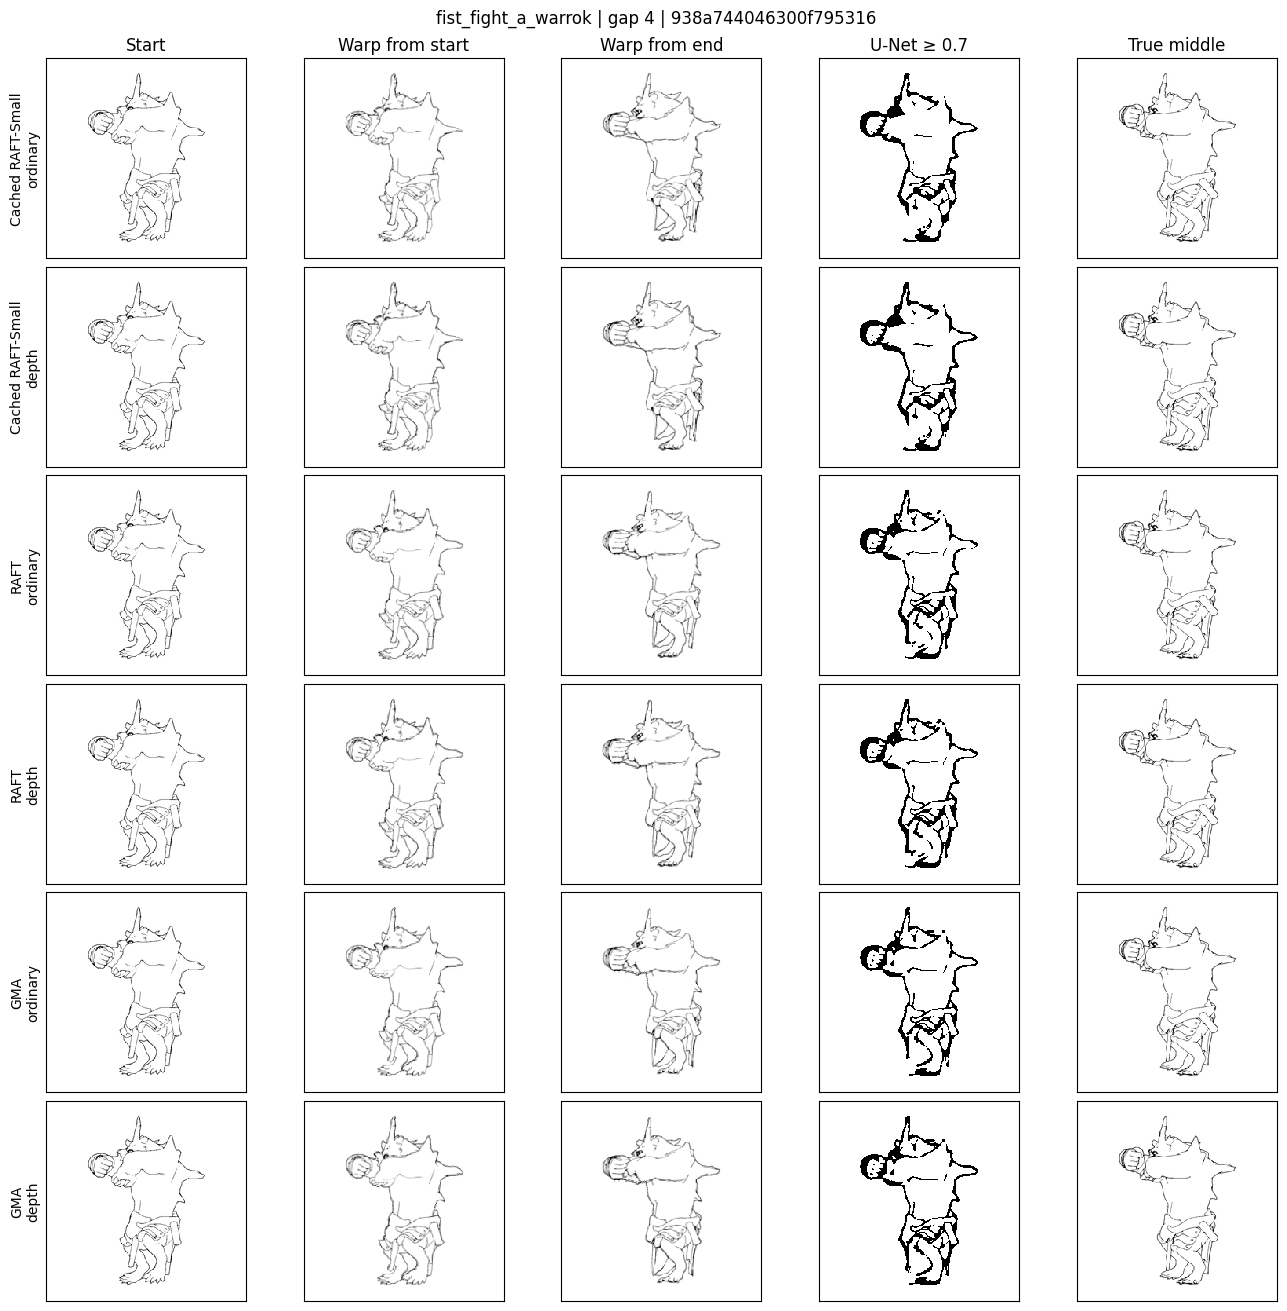

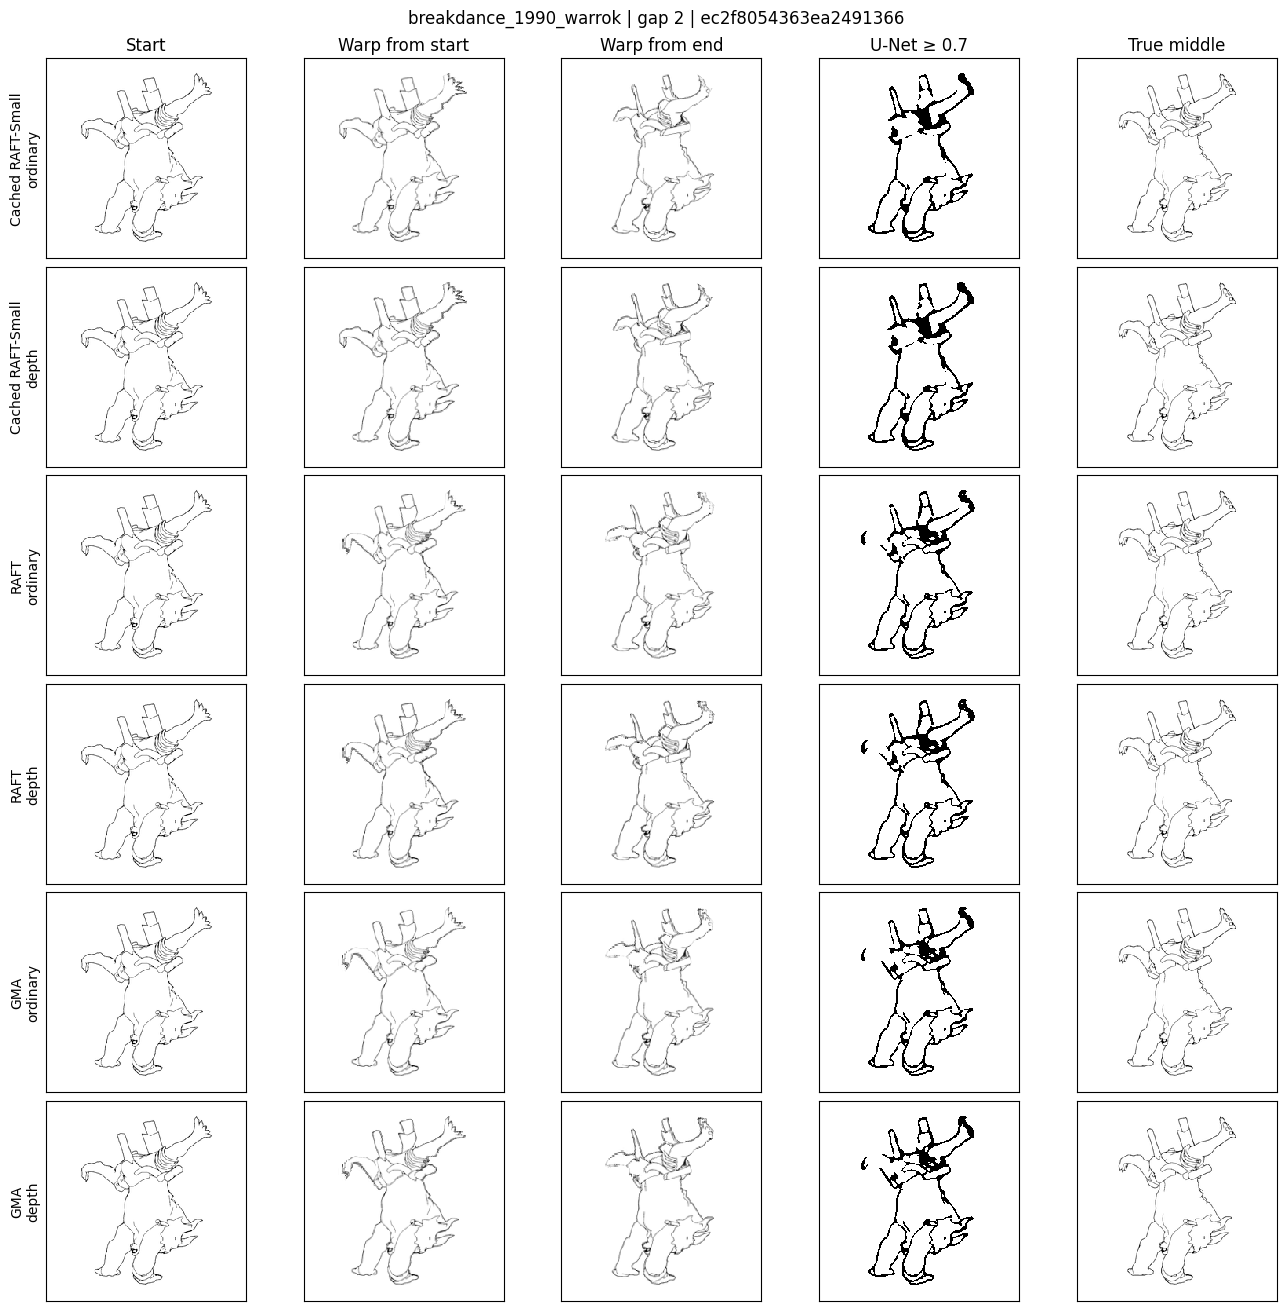

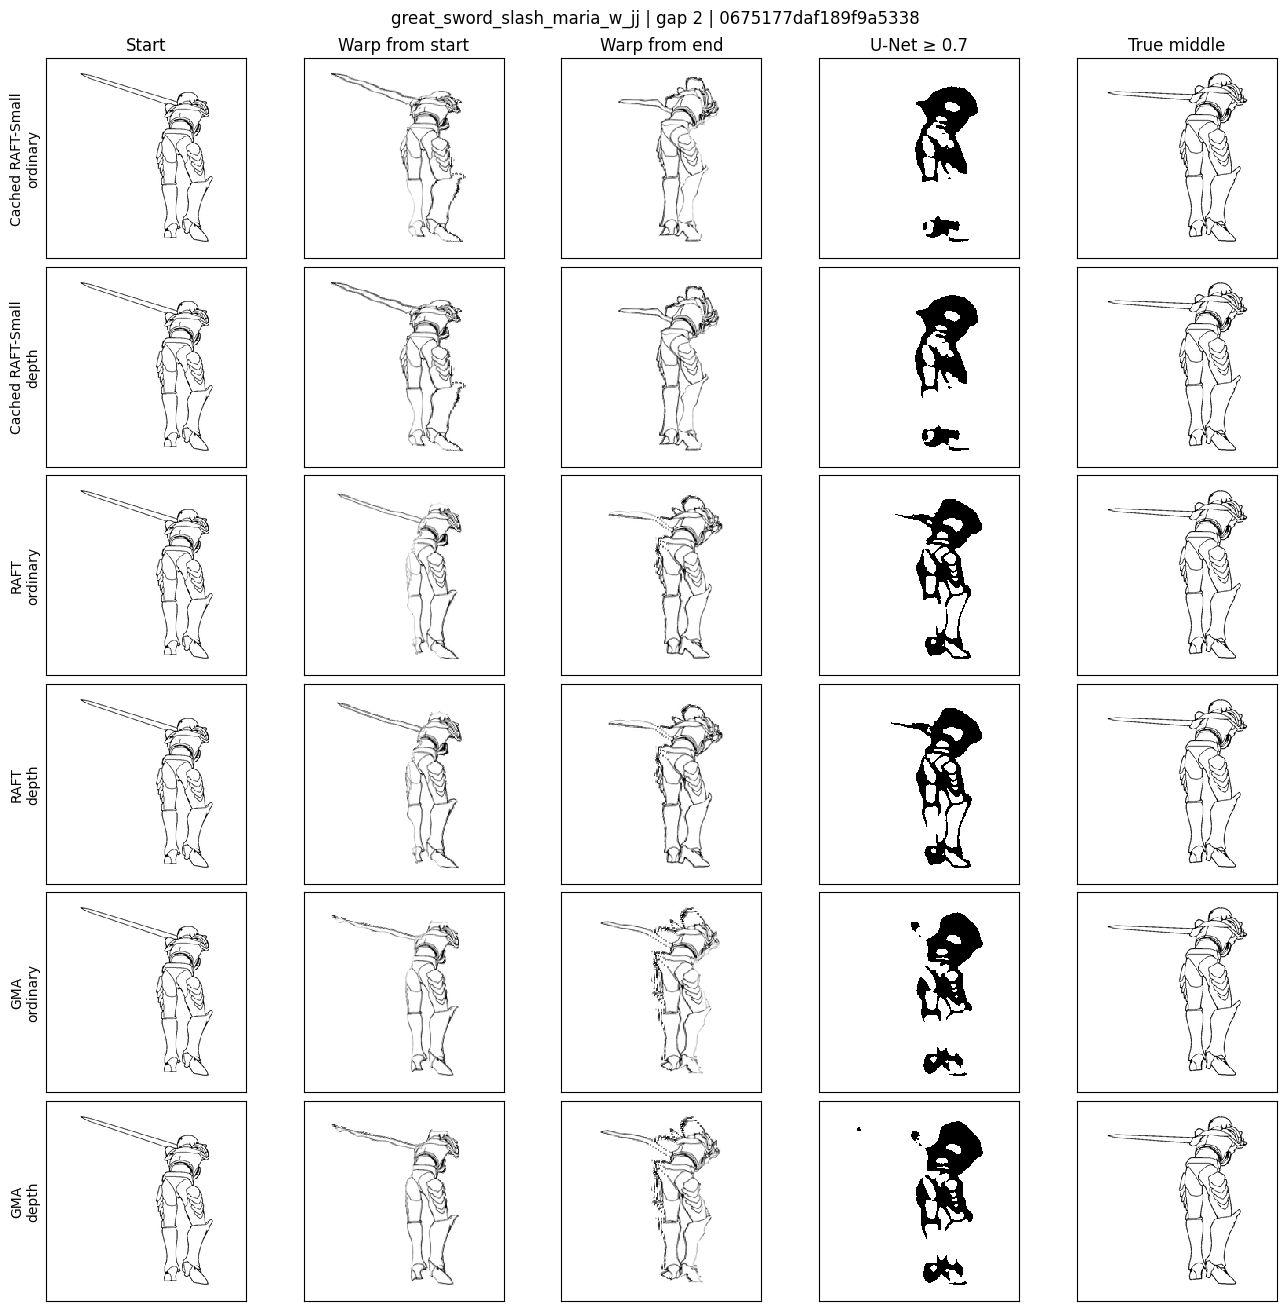

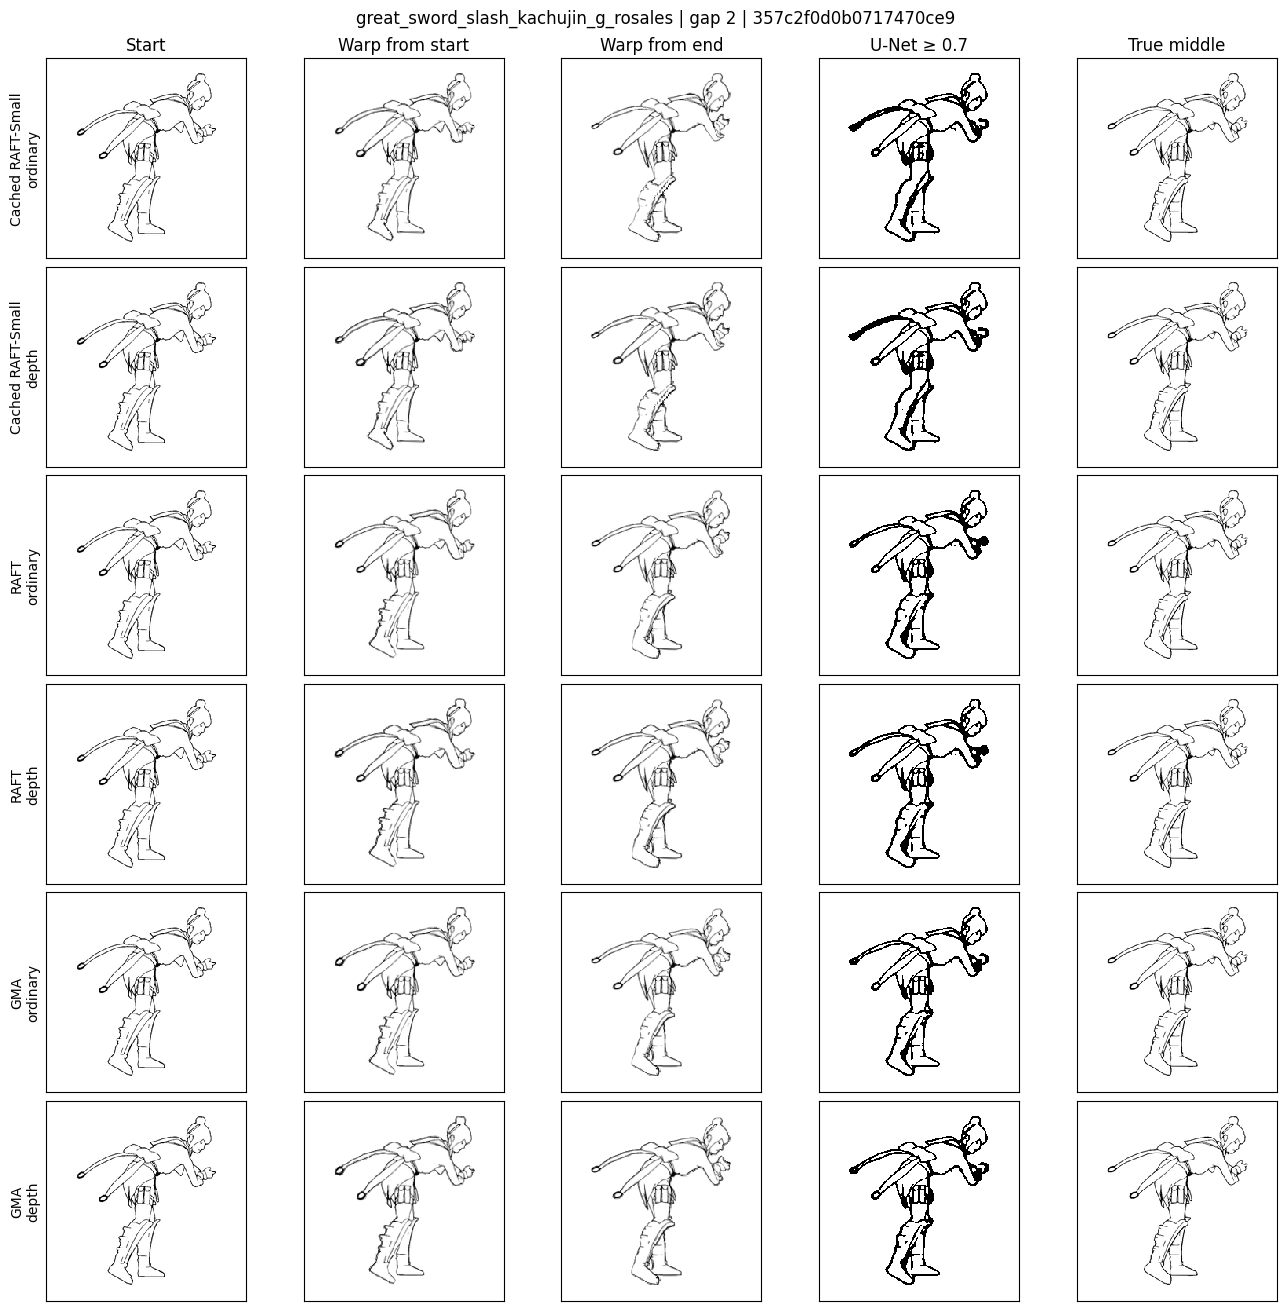

line_f1  chamfer_px      mae  ink_ratio
method            mode                                             
Cached RAFT-Small ordinary  0.78460     1.31620  0.09346    4.84353
                  depth     0.78416     1.32059  0.09426    4.88746
RAFT              ordinary  0.79911     1.31027  0.08468    4.31532
                  depth     0.79866     1.30710  0.08552    4.35334
GMA               ordinary  0.80094     1.28012  0.08509    4.39980
                  depth     0.80053     1.28627  0.08590    4.43308

Effect of adding depth to each flow model (depth minus ordinary):


,line_f1,chamfer_px,mae,ink_ratio
method,,,,
Cached RAFT-Small,-0.00044,0.00439,0.00080,0.04393
RAFT,-0.00045,-0.00317,0.00084,0.03802
GMA,-0.00041,0.00615,0.00081,0.03328


Saved: /kaggle/working/interframes_depth07/65c608884d/flow_comparison/depth_strength_3_preview_0.7


In [ ]:
# Compare ordinary vs. depth-guided warps for each motion model.
STRENGTH = 3.0  # Same depth strength as the original notebook 07 experiment.
INK_CUTOFF = 0.70  # Preview only. Metrics stay at 0.50 for comparison.

methods = ["Cached RAFT-Small", "RAFT", "GMA"]
save_dir = flow_dir / f"depth_strength_{STRENGTH:g}_preview_{INK_CUTOFF:g}"
save_dir.mkdir(exist_ok=True)
records = []

for i, row in enumerate(tqdm(cases, desc="Flow × depth comparison")):
    a, b, target = [raster.read_ink(DATA / row[k]) for k in ("a", "b", "target")]
    endpoint_depths = [depths[row["a"]], depths[row["b"]]]
    lows = [
        flows[row["cache_index"]],
        np.load(flow_dir / f"RAFT_{i:03d}.npy"),
        np.load(flow_dir / f"GMA_{i:03d}.npy"),
    ]

    if i < SHOW:
        fig, axes = plt.subplots(6, 5, figsize=(13, 13), constrained_layout=True)

    for j, (method, low) in enumerate(zip(methods, lows)):
        ordinary = raster.features_from_low(a, b, low)
        guided = ordinary.copy()

        for k, depth in enumerate(endpoint_depths):
            flow = raster.upsample_low(low[k], a.shape[0]).transpose(2, 0, 1)
            guided[..., 2 + k] = depth_warp(
                ordinary[..., k], flow, depth, ordinary[..., 6 + k]
            )

        # Same model and same flow. Only the two warped ink channels differ.
        pair = np.stack([ordinary, guided])
        preds = tf.sigmoid(tf.cast(net(pair, training=False), tf.float32)).numpy()[
            ..., 0
        ]
        if not np.isfinite(preds).all():
            raise ValueError(f"Invalid prediction: {method}, {row['id']}")

        for k, mode in enumerate(("ordinary", "depth")):
            pred = preds[k]
            score = raster.line_scores(pred, target, threshold=0.5, tolerance=2)
            records.append(
                dict(
                    id=row["id"],
                    gap=row["gap"],
                    method=method,
                    mode=mode,
                    target_fraction=(target >= 0.5).mean(),
                    **score,
                )
            )

            if i < SHOW:
                axes_row = axes[2 * j + k]
                images = [
                    a,
                    pair[k, ..., 2],
                    pair[k, ..., 3],
                    pred >= INK_CUTOFF,
                    target,
                ]
                for ax, image in zip(axes_row, images):
                    ax.imshow(
                        image, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest"
                    )
                    ax.set_xticks([])
                    ax.set_yticks([])
                axes_row[0].set_ylabel(f"{method}\n{mode}")

    if i < SHOW:
        titles = [
            "Start",
            "Warp from start",
            "Warp from end",
            f"U-Net ≥ {INK_CUTOFF:g}",
            "True middle",
        ]
        for ax, title in zip(axes[0], titles):
            ax.set_title(title)
        fig.suptitle(f"{row['sequence']} | gap {row['gap']} | {row['id']}")
        fig.savefig(save_dir / f"case_{i:03d}.png", dpi=140)
        plt.show()
        plt.close(fig)

df = pd.DataFrame(records)
df.to_csv(save_dir / "per_pair.csv", index=False)

avg = df.groupby(["method", "mode"], sort=False).mean(numeric_only=True)
avg["ink_ratio"] = avg["ink_fraction"] / avg["target_fraction"]
summary = avg[["line_f1", "chamfer_px", "mae", "ink_ratio"]]
delta = summary.xs("depth", level="mode") - summary.xs("ordinary", level="mode")

display(summary.round(5))
print("Effect of adding depth to each flow model (depth minus ordinary):")
display(delta.round(5))

summary.to_csv(save_dir / "summary.csv")
delta.to_csv(save_dir / "depth_minus_ordinary.csv")
print("Saved:", save_dir)

## Write the coarse and full-resolution worker

Replace the worker with a version that saves both compact and full-resolution RAFT/GMA motion. The `Overwriting` message is expected.

In [ ]:
%%writefile /kaggle/working/animerun_flow07.py
import argparse
import json
import sys
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from tqdm import tqdm

name, repo, checkpoint, data, output, steps = sys.argv[1:]
root, out = Path(data), Path(output)
sys.path.insert(0, str(Path(repo) / "core"))

if name == "RAFT":
    from raft import RAFT as FlowModel
elif name == "GMA":
    from network import RAFTGMA as FlowModel
else:
    raise ValueError(f"Unknown model: {name}")

args = argparse.Namespace(
    small=False,
    mixed_precision=False,
    alternate_corr=False,
    dropout=0.0,
    num_heads=1,
    position_only=False,
    position_and_content=False,
)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = FlowModel(args)
weights = torch.load(checkpoint, map_location="cpu", weights_only=True)
model.load_state_dict({k.removeprefix("module."): v for k, v in weights.items()})
model.to(device).eval()


def read_frame(relative):
    with Image.open(root / relative) as im:
        rgb = np.array(im.convert("RGB"))
    return torch.from_numpy(rgb).permute(2, 0, 1).float()


rows = json.loads((out / "cases.json").read_text())
with torch.inference_mode():
    for i, row in enumerate(tqdm(rows, desc=f"AnimeRun {name}")):
        coarse_path = out / f"{name}_{i:03d}.npy"
        full_path = out / f"{name}_{i:03d}_full.npy"
        if coarse_path.is_file() and full_path.is_file():
            continue

        pair = torch.stack([read_frame(row["a"]), read_frame(row["b"])]).to(device)
        coarse, full = model(pair, pair.flip(0), iters=int(steps), test_mode=True)
        h, w = pair.shape[-2:]
        assert coarse.shape == (2, 2, h // 8, w // 8)
        assert full.shape == (2, 2, h, w)

        for path, field in ((coarse_path, coarse), (full_path, full)):
            if not torch.isfinite(field).all():
                raise ValueError(f"Invalid flow for {row['id']}: {path.name}")
            tmp = path.with_suffix(".part.npy")
            np.save(tmp, field.permute(0, 2, 3, 1).cpu().numpy().astype(np.float16))
            tmp.replace(path)

Overwriting /kaggle/working/animerun_flow07.py


## Compare five U-Net input variants

Compare cached RAFT-small with coarse and full-resolution motion from RAFT and GMA. `PREVIEW_CUTOFF` changes displayed drawings; `METRIC_CUTOFF=0.50` keeps scoring consistent.

AnimeRun RAFT:   0%|          | 0/20 [00:00<?, ?it/s]/kaggle/temp/animerun_models/RAFT/core/raft.py:99: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/kaggle/temp/animerun_models/RAFT/core/raft.py:110: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/kaggle/temp/animerun_models/RAFT/core/raft.py:127: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
 

U-Net comparisons:   0%|          | 0/20 [00:00<?, ?it/s]

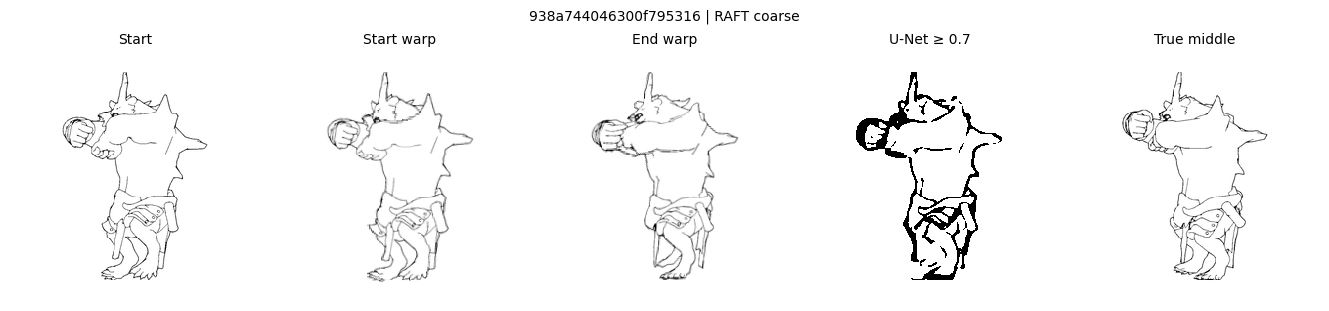

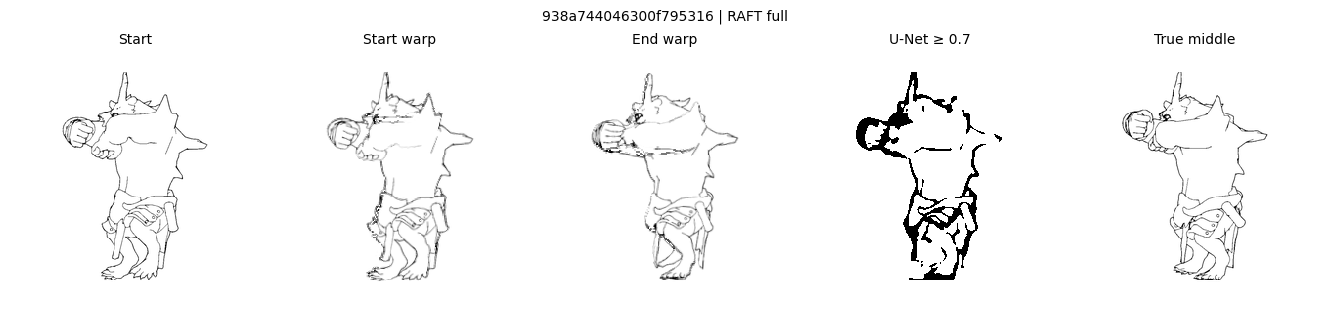

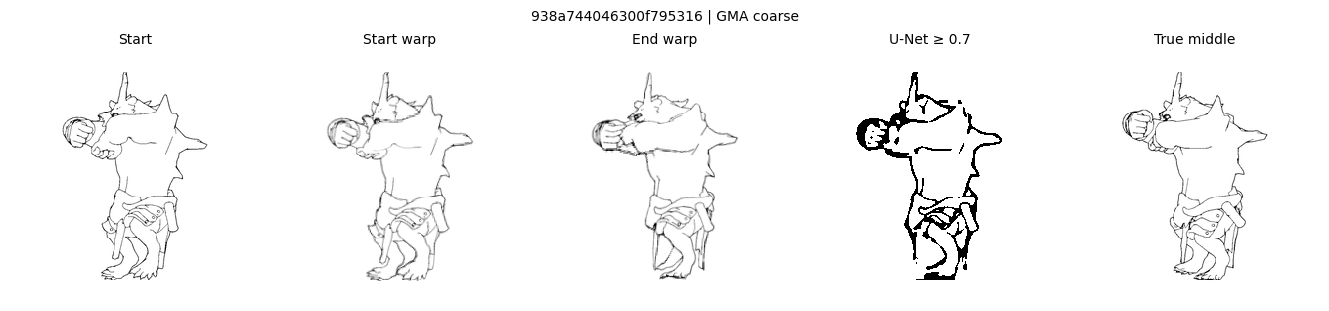

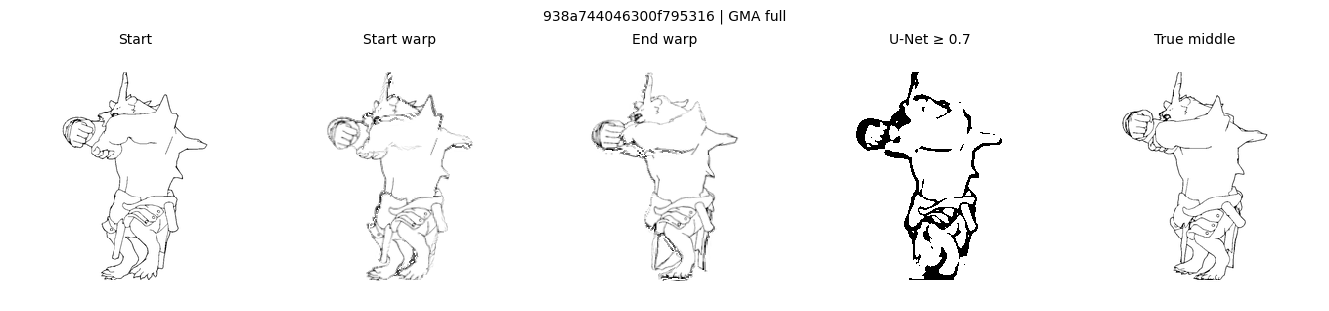

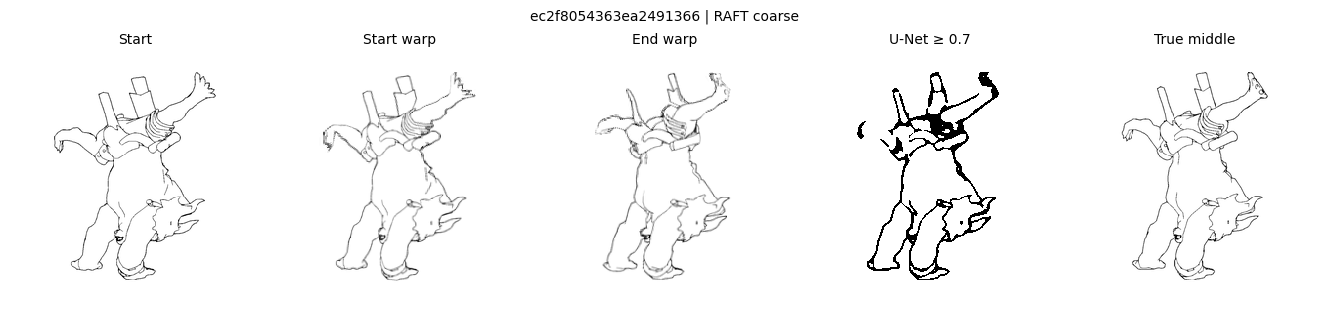

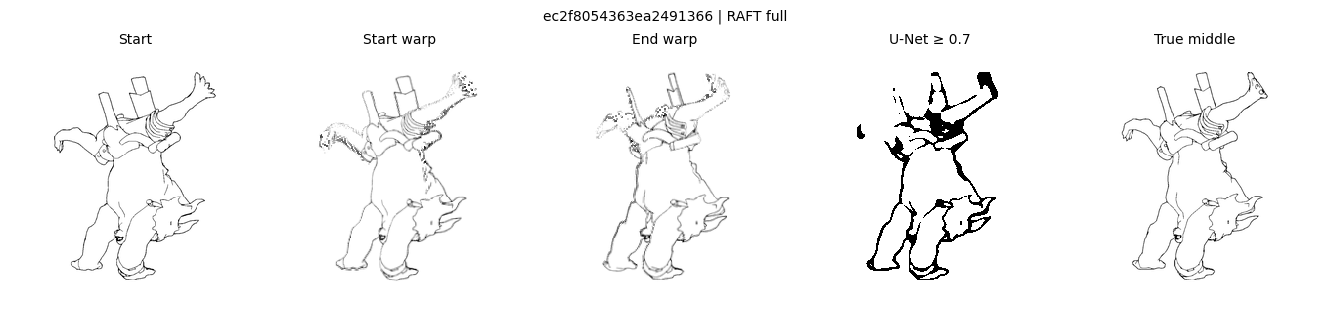

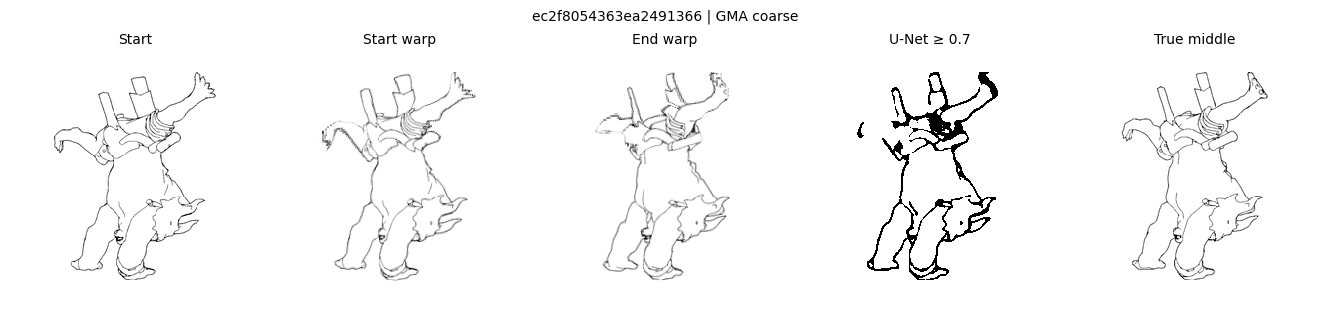

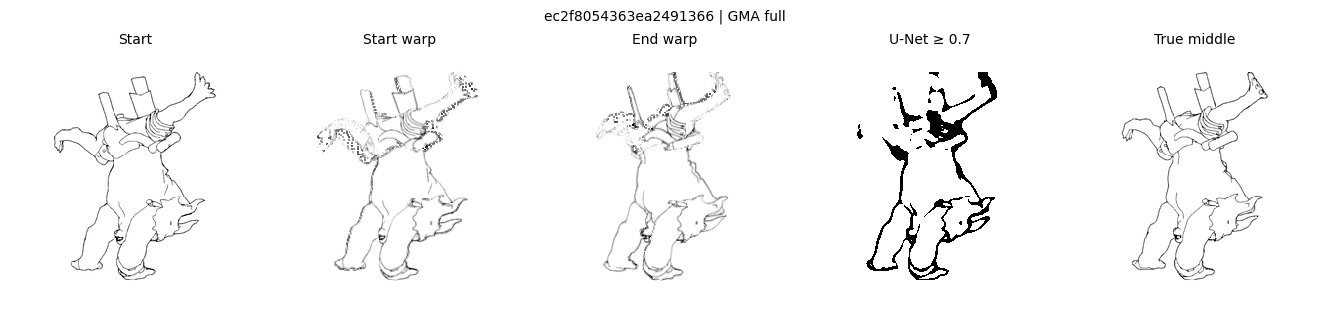

,line_f1,chamfer_px,mae,ink_ratio
method,,,,
Cached RAFT-Small,0.78458,1.31627,0.09346,4.84338
RAFT coarse,0.79913,1.31022,0.08468,4.31529
RAFT full,0.78754,1.34365,0.09325,4.83796
GMA coarse,0.80093,1.28022,0.08509,4.39988
GMA full,0.78419,1.32813,0.09422,4.92893


1B complete: 20 cases × 5 predictions saved in /kaggle/working/interframes_depth07/65c608884d/flow_comparison/resolution_comparison


In [ ]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from huggingface_hub import hf_hub_download
from IPython.display import display
from tqdm.auto import tqdm

PREVIEW_CUTOFF = 0.70
METRIC_CUTOFF = 0.50
SHOW_PAIRS = 2

flow_dir = folder / "flow_comparison"
out07 = flow_dir / "resolution_comparison"
out07.mkdir(parents=True, exist_ok=True)
repos = Path("/kaggle/temp/animerun_models")
repos.mkdir(parents=True, exist_ok=True)

case_file = flow_dir / "cases.json"
if case_file.exists() and json.loads(case_file.read_text()) != cases:
    raise ValueError(
        "Cached flow indices belong to different cases. Use a fresh flow_dir."
    )
case_file.write_text(json.dumps(cases))

specs = {
    "RAFT": ("princeton-vl/RAFT", "20000_raft-animerun-v2-ft_again.pth"),
    "GMA": ("zacjiang/GMA", "20000_gma-animerun-v2-ft.pth"),
}
steps = str(json.loads((DATA / "config.json").read_text()).get("raft_iterations", 12))

for name, (url, filename) in specs.items():
    complete = all(
        (flow_dir / f"{name}_{i:03d}{suffix}.npy").is_file()
        for i in range(len(cases))
        for suffix in ("", "_full")
    )
    if complete:
        print(f"{name}: reusing all saved flows.", flush=True)
        continue
    if not (repos / name / "core").is_dir():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                f"https://github.com/{url}.git",
                str(repos / name),
            ],
            check=True,
        )
    checkpoint = hf_hub_download("dreMaz/AnimeRun_ckpt", filename)
    subprocess.run(
        [
            sys.executable,
            "/kaggle/working/animerun_flow07.py",
            name,
            str(repos / name),
            checkpoint,
            str(DATA),
            str(flow_dir),
            steps,
        ],
        check=True,
    )

methods07 = ["Cached RAFT-Small", "RAFT coarse", "RAFT full", "GMA coarse", "GMA full"]


def prediction_path(case_id, method):
    return out07 / f"{case_id}_{method.replace(' ', '_')}.npy"


def score07(row, method, pred, target):
    metrics = raster.line_scores(pred, target, threshold=METRIC_CUTOFF, tolerance=2)
    return dict(
        id=row["id"],
        gap=row["gap"],
        method=method,
        target_fraction=float((target >= METRIC_CUTOFF).mean()),
        **metrics,
    )


def summary07(df):
    avg = df.groupby("method", sort=False).mean(numeric_only=True)
    avg["ink_ratio"] = avg["ink_fraction"] / avg["target_fraction"]
    return avg[["line_f1", "chamfer_px", "mae", "ink_ratio"]]


def show07(views, title, dest):
    fig, axes = plt.subplots(
        1, len(views), figsize=(2.65 * len(views), 3), constrained_layout=True
    )
    for ax, (label, image) in zip(axes, views):
        ax.imshow(image, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(label, fontsize=10)
        ax.axis("off")
    fig.suptitle(title, fontsize=10)
    fig.savefig(dest, dpi=140)
    plt.show()
    plt.close(fig)


records = []
for i, row in enumerate(tqdm(cases, desc="U-Net comparisons")):
    cid = row["id"]
    a, b, target = [raster.read_ink(DATA / row[k]) for k in ("a", "b", "target")]
    inputs = {"Cached RAFT-Small": raster.row_features(DATA, row, flows)}

    for name in specs:
        low = np.load(flow_dir / f"{name}_{i:03d}.npy")
        full = np.load(flow_dir / f"{name}_{i:03d}_full.npy").astype(np.float32)
        coarse_x = raster.features_from_low(a, b, low)
        full_x = coarse_x.copy()
        for j, ink in enumerate((a, b)):
            # Full flow is already in image pixels. Use it directly.
            warp, coverage = raster.forward_splat(ink, full[j].transpose(2, 0, 1))
            full_x[..., 2 + j] = warp
            full_x[..., 6 + j] = coverage
        inputs[f"{name} coarse"] = coarse_x
        inputs[f"{name} full"] = full_x

    missing = [m for m in methods07 if not prediction_path(cid, m).is_file()]
    if missing:
        batch = np.stack([inputs[m] for m in missing])
        preds = tf.sigmoid(tf.cast(net(batch, training=False), tf.float32)).numpy()[
            ..., 0
        ]
        if not np.isfinite(preds).all():
            raise ValueError(f"Invalid U-Net prediction: {cid}")
        for method, pred in zip(missing, preds):
            dest = prediction_path(cid, method)
            tmp = dest.with_suffix(".part.npy")
            np.save(tmp, pred)
            tmp.replace(dest)

    for method in methods07:
        pred = np.load(prediction_path(cid, method))
        records.append(score07(row, method, pred, target))
        if i < SHOW_PAIRS and method != "Cached RAFT-Small":
            x = inputs[method]
            show07(
                [
                    ("Start", a),
                    ("Start warp", x[..., 2]),
                    ("End warp", x[..., 3]),
                    (f"U-Net ≥ {PREVIEW_CUTOFF:g}", pred >= PREVIEW_CUTOFF),
                    ("True middle", target),
                ],
                f"{cid} | {method}",
                prediction_path(cid, method).with_suffix(".png"),
            )

flow_scores = pd.DataFrame(records)
flow_scores.to_csv(out07 / "per_pair.csv", index=False)
flow_summary = summary07(flow_scores)
flow_summary.to_csv(out07 / "summary.csv")
display(flow_summary.round(5))
print(
    f"1B complete: {len(cases)} cases × {len(methods07)} predictions saved in {out07}"
)

## Prepare matching AnimeInbet inputs

Select four validation pairs and obtain their original endpoint PNGs and `Line*.json` graphs. Set `RAW_ZIP` if the original ML240 archive is attached. Reuse downloaded files and the saved `epoch_20.pt` model when available.

AnimeInbet receives endpoint drawings and graphs. Its comparison here uses these selected cases, not the full published benchmark.

In [ ]:
%pip -q install scikit-network easydict gdown

import re
import zipfile
from contextlib import ExitStack
import gdown
from huggingface_hub import HfFileSystem

N_ANIME = 4
RAW_ZIP = None
chosen = cases[:N_ANIME]
assert chosen, "No validation cases selected."

anime_dir = out07 / "animeinbet"
anime_dir.mkdir(exist_ok=True)
repo = Path("/kaggle/temp/AnimeInbet07")
if not (repo / ".git").exists():
    subprocess.run(
        [
            "git",
            "clone",
            "--quiet",
            "https://github.com/lisiyao21/AnimeInbet.git",
            str(repo),
        ],
        check=True,
    )
subprocess.run(
    [
        "git",
        "-C",
        str(repo),
        "checkout",
        "--quiet",
        "cc5554feb9d8943f1fc5f0b90854ef15cd3e8335",
    ],
    check=True,
)

ckpt = repo / "epoch_20.pt"
if not ckpt.is_file():
    tmp = ckpt.with_suffix(".part")
    if not gdown.download(
        id="1cemJCBNdcTvJ9LWCA_5LmDDorwEb-u7M", output=str(tmp), quiet=False
    ):
        raise RuntimeError("Could not download the authors' epoch_20.pt from Drive.")
    tmp.replace(ckpt)

needed = []
for row in chosen:
    for j, n in enumerate(
        (row["middle_number"] - row["gap"], row["middle_number"] + row["gap"])
    ):
        for kind, ext in (("frames", ".png"), ("labels", ".json")):
            dest = anime_dir / "inputs" / "pairs" / kind / row["id"] / f"{j}{ext}"
            if not dest.is_file() or dest.stat().st_size == 0:
                needed.append(((kind, row["sequence"], n), dest))

if needed:
    remote = (
        "camenduru/AnimeInbet@cb88360947cf5f25c7bbe3858137c4df7ae2a08c/ml240data.zip"
    )
    with ExitStack() as stack:
        source = RAW_ZIP or stack.enter_context(HfFileSystem().open(remote, "rb"))
        archive = stack.enter_context(zipfile.ZipFile(source))
        wanted = {key for key, _ in needed}
        members = {}
        for member in archive.namelist():
            p = Path(member)
            # This original partition is the validation split in notebook 07.
            if "__MACOSX" in p.parts or p.parts[-5:-3] != (
                "ml144_norm_100_44_split",
                "test",
            ):
                continue
            kind, seq = p.parts[-3:-1]
            match = re.search(r"(\d+)$", p.stem)
            if match and (kind, p.suffix.lower()) in {
                ("frames", ".png"),
                ("labels", ".json"),
            }:
                key = (kind, seq, int(match[1]))
                if key in wanted:
                    members[key] = member

        absent = wanted - members.keys()
        if absent:
            raise FileNotFoundError(
                f"Endpoint files missing from original archive: {list(absent)[:3]}"
            )
        for key, dest in tqdm(needed, desc="Fetch endpoints"):
            dest.parent.mkdir(parents=True, exist_ok=True)
            tmp = dest.with_suffix(".part")
            tmp.write_bytes(archive.read(members[key]))
            tmp.replace(dest)

print(f"2A complete: checkpoint and {len(chosen)} endpoint pairs ready.")

Note: you may need to restart the kernel to use updated packages.
2A complete: checkpoint and 4 endpoint pairs ready.


## Compare AnimeInbet and test display cutoffs

Check that the U-Net predictions exist, run AnimeInbet on the matching endpoints, and render its predicted lines. Reuse completed midpoint images. The final cell tests GMA-coarse ink cutoffs from 0.50 to 0.95 while holding the reference cutoff at 0.50.

Len of Frame is  4
Len of Label is  4


AnimeInbet midpoint:   0%|          | 0/3 [00:00<?, ?it/s]

/kaggle/temp/AnimeInbet07/models/inbetweener_with_mask_with_spec.py:326: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
  desc0 = desc0 + self.tenc(desc0.new_tensor(spec0))
/kaggle/temp/AnimeInbet07/models/inbetweener_with_mask_with_spec.py:327: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
  desc1 = desc1 + self.tenc(desc1.new_tensor(spec1))


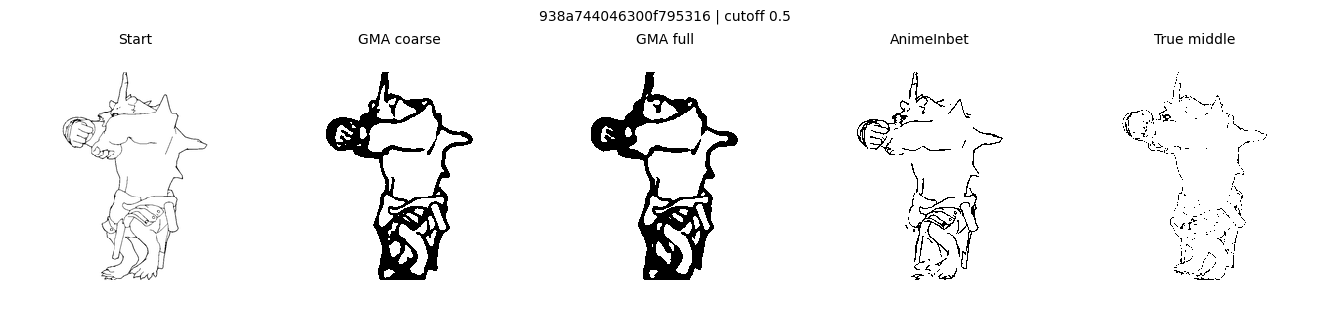

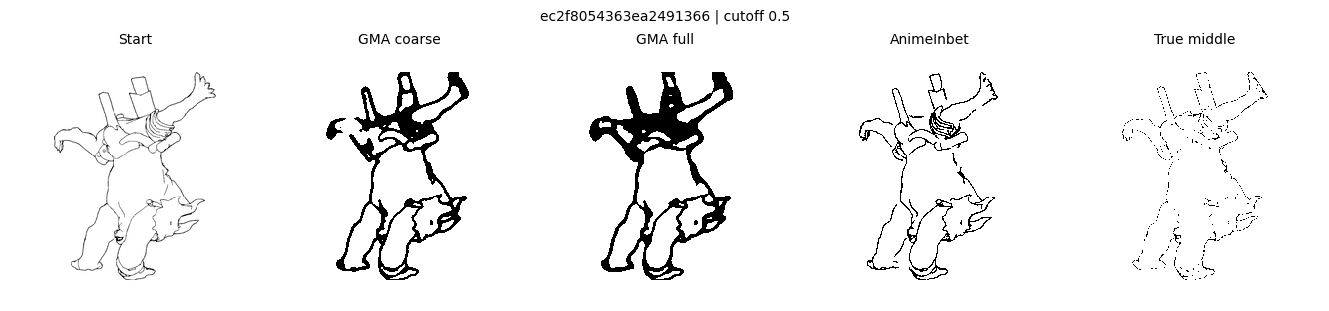

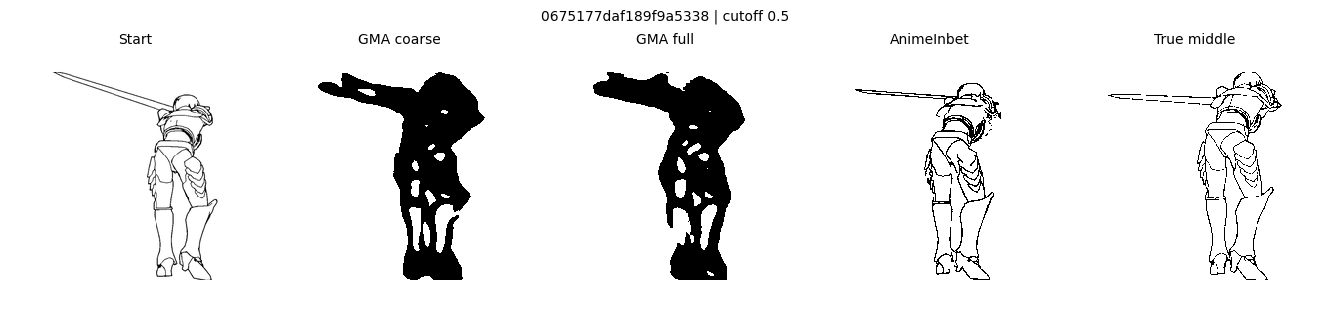

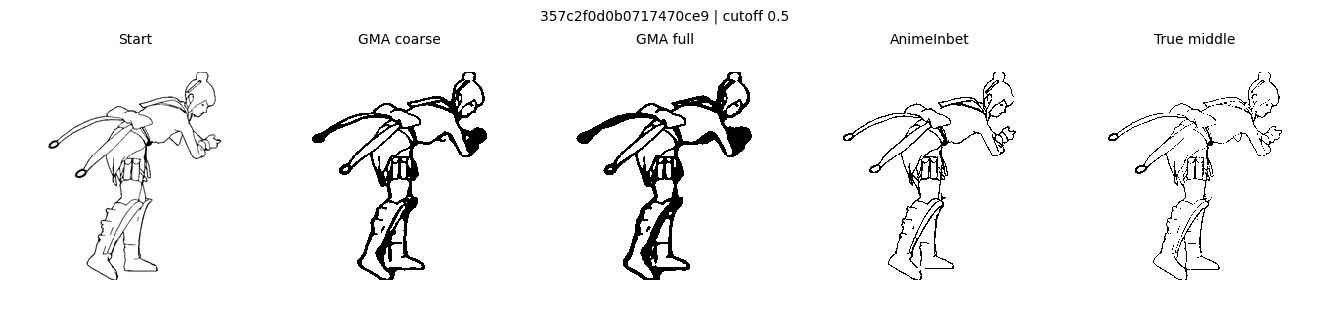

,line_f1,chamfer_px,mae,ink_ratio
method,,,,
Cached RAFT-Small,0.71401,1.58753,0.09255,5.28642
RAFT coarse,0.73119,1.47808,0.08601,4.93701
RAFT full,0.72266,1.41725,0.09591,5.56348
GMA coarse,0.73323,1.39982,0.08843,5.15322
GMA full,0.71022,1.53525,0.09638,5.66125
AnimeInbet + endpoint graphs,0.69887,1.95335,0.04132,1.66093


2B complete: all six methods compared on the same 4 pairs.
Results: /kaggle/working/interframes_depth07/65c608884d/flow_comparison/resolution_comparison/animeinbet


In [ ]:
import importlib.util
import cv2
import torch
import yaml
from easydict import EasyDict
from PIL import Image

by_id = {r["id"]: r for r in chosen}
required = [prediction_path(cid, method) for cid in by_id for method in methods07]
missing = [p for p in required if not p.is_file()]
if missing or not (out07 / "per_pair.csv").is_file():
    raise FileNotFoundError(
        f"Run 1B to its '1B complete' message first. "
        f"Missing predictions: {len(missing)}. Comparison folder: {out07}"
    )


def load_source(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


pending = {cid for cid in by_id if not (anime_dir / f"{cid}_middle.png").is_file()}
if pending:
    model_src = load_source(
        "anime07_model", repo / "models/inbetweener_with_mask_with_spec.py"
    )
    data_src = load_source("anime07_data", repo / "datasets/vd_seq.py")
    cfg = EasyDict(
        yaml.safe_load((repo / "configs/cr_inbetweener_full.yaml").read_text())
    )
    device07 = "cuda" if torch.cuda.is_available() else "cpu"
    anime = model_src.InbetweenerTM(cfg.model)
    weights = torch.load(ckpt, map_location="cpu", weights_only=False)["model"]
    anime.load_state_dict(
        {k.removeprefix("module."): v for k, v in weights.items()}, strict=True
    )
    anime.to(device07).eval()

    dataset = data_src.VideoLinSeq(str(anime_dir / "inputs"), split="pairs")
    indices = {
        Path(pair[0]).parent.name: i for i, pair in enumerate(dataset.label_list)
    }
    if pending - indices.keys():
        raise ValueError("Some endpoint pairs are missing. Rerun 2A.")

    for cid in tqdm(sorted(pending), desc="AnimeInbet midpoint"):
        sample = dataset[indices[cid]]
        batch = {"gen_vid": True}
        for j, count in enumerate(("ms", "ns")):
            for base in ("image", "keypoints", "mask", "spec"):
                key = f"{base}{j}"
                batch[key] = torch.as_tensor(sample[key]).unsqueeze(0).to(device07)
            batch[count] = torch.tensor([sample[count]], device=device07)
            batch[f"topo{j}"] = sample[f"topo{j}"]

        with torch.inference_mode():
            result = anime(batch)

        h, w = sample["image0"].shape[-2:]
        canvas = np.full((h, w), 255, dtype=np.uint8)
        for j in (0, 1):
            points = sample[f"keypoints{j}"].numpy()
            motion = result[f"r{j}"][0].float().cpu().numpy()
            visible = result[f"vb{j}"][0].float().cpu().numpy() > 0
            xy = (points + 0.5 * motion).astype(np.int32)
            for u, neighbors in enumerate(sample[f"topo{j}"][0]):
                for v in neighbors:
                    if u != v and visible[u] and visible[v]:
                        cv2.line(canvas, tuple(xy[u]), tuple(xy[v]), 0, thickness=2)

        size = raster.read_ink(DATA / by_id[cid]["a"]).shape[0]
        image = raster.prepare_image(Image.fromarray(canvas), size=size)
        dest = anime_dir / f"{cid}_middle.png"
        tmp = dest.with_suffix(".part.png")
        image.save(tmp)
        tmp.replace(dest)

# Score and display every chosen case, including previously saved PNGs.
anime_records = []
for row in chosen:
    cid = row["id"]
    target = raster.read_ink(DATA / row["target"])
    pred = raster.read_ink(anime_dir / f"{cid}_middle.png")
    anime_records.append(score07(row, "AnimeInbet + endpoint graphs", pred, target))

    views = [("Start", raster.read_ink(DATA / row["a"]))]
    for method in ("GMA coarse", "GMA full"):
        drawing = np.load(prediction_path(cid, method))
        views.append((method, drawing >= METRIC_CUTOFF))
    views += [
        ("AnimeInbet", pred >= METRIC_CUTOFF),
        ("True middle", target >= METRIC_CUTOFF),
    ]
    show07(
        views, f"{cid} | cutoff {METRIC_CUTOFF:g}", anime_dir / f"{cid}_comparison.png"
    )

saved_scores = pd.read_csv(out07 / "per_pair.csv", dtype={"id": str})
matched = pd.concat(
    [saved_scores[saved_scores["id"].isin(by_id)], pd.DataFrame(anime_records)],
    ignore_index=True,
)
assert len(matched) == len(chosen) * (len(methods07) + 1)
matched.to_csv(anime_dir / "matched_per_pair.csv", index=False)
matched_summary = summary07(matched)
matched_summary.to_csv(anime_dir / "matched_summary.csv")
display(matched_summary.round(5))
print(f"2B complete: all six methods compared on the same {len(chosen)} pairs.")
print("Results:", anime_dir)

Check ink cutoffs:   0%|          | 0/20 [00:00<?, ?it/s]

,line_f1,chamfer_px,ink_ratio
cutoff,,,
0.50,0.8009,1.2802,4.3999
0.60,0.8076,1.4874,3.6012
0.70,0.7963,2.0232,2.6198
0.80,0.7461,5.1500,1.7096
0.85,0.7057,38.6247,1.2670
0.90,0.6243,40.3708,0.7752
0.95,0.4598,64.4765,0.3127


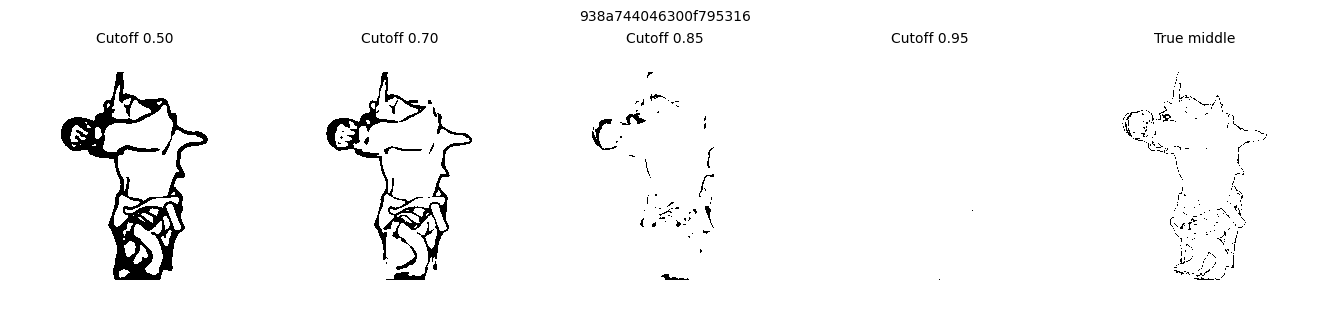

In [ ]:
cutoffs = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]
results = []

for row in tqdm(cases, desc="Check ink cutoffs"):
    pred = np.load(prediction_path(row["id"], "GMA coarse"))
    target = raster.read_ink(DATA / row["target"])
    true_ink = target >= 0.50  # Keep the reference fixed across comparisons.

    for cutoff in cutoffs:
        drawing = pred >= cutoff
        score = raster.line_scores(
            drawing.astype(np.float32),
            true_ink.astype(np.float32),
            threshold=0.50,
            tolerance=2,
        )
        results.append(
            {
                "cutoff": cutoff,
                "line_f1": score["line_f1"],
                "chamfer_px": score["chamfer_px"],
                "predicted_ink": drawing.sum(),
                "target_ink": true_ink.sum(),
            }
        )

table = (
    pd.DataFrame(results)
    .groupby("cutoff")
    .agg(
        line_f1=("line_f1", "mean"),
        chamfer_px=("chamfer_px", "mean"),
        predicted_ink=("predicted_ink", "sum"),
        target_ink=("target_ink", "sum"),
    )
)
table["ink_ratio"] = table["predicted_ink"] / table["target_ink"]
table = table[["line_f1", "chamfer_px", "ink_ratio"]]
display(table.round(4))
table.to_csv(out07 / "gma_coarse_cutoff_sweep.csv")

# Change this index to inspect a different drawing.
row = cases[0]
pred = np.load(prediction_path(row["id"], "GMA coarse"))
target = raster.read_ink(DATA / row["target"])
views = [(f"Cutoff {c:.2f}", pred >= c) for c in (0.50, 0.70, 0.85, 0.95)]
views.append(("True middle", target >= 0.50))
show07(views, row["id"], out07 / f"{row['id']}_cutoff_sweep.png")